In [1]:
print("GeoShield AI notebook is working!")

GeoShield AI notebook is working!


In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("GeoPandas:", gpd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

Pandas: 3.0.6
NumPy: 2.5.3
GeoPandas: 1.1.4
Matplotlib: 3.11.2


In [3]:
road_data = {
    "road_id": ["R001", "R002", "R003"],
    "latitude": [17.3850, 17.4000, 17.4200],
    "longitude": [78.4867, 78.4900, 78.5000],
    "damage_level": ["Low", "High", "Medium"]
}

df = pd.DataFrame(road_data)

df

,road_id,latitude,longitude,damage_level
0,R001,17.385,78.4867,Low
1,R002,17.400,78.4900,High
2,R003,17.420,78.5000,Medium


In [5]:
len(df)

3

In [6]:
df["damage_level"].value_counts()

damage_level
Low       1
High      1
Medium    1
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   road_id       3 non-null      str    
 1   latitude      3 non-null      float64
 2   longitude     3 non-null      float64
 3   damage_level  3 non-null      str    
dtypes: float64(2), str(2)
memory usage: 228.0 bytes


In [8]:
df.describe()

,latitude,longitude
count,3.000000,3.000000
mean,17.401667,78.492233
std,0.017559,0.006926
min,17.385000,78.486700
25%,17.392500,78.488350
50%,17.400000,78.490000
75%,17.410000,78.495000
max,17.420000,78.500000


<Axes: xlabel='longitude', ylabel='latitude'>

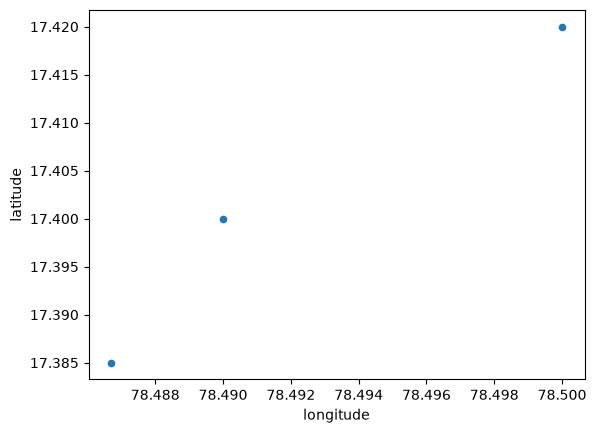

In [9]:
df.plot(
    x="longitude",
    y="latitude",
    kind="scatter"
)

In [10]:
import geopandas as gpd

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326"
)

gdf


,road_id,latitude,longitude,damage_level,geometry
0,R001,17.385,78.4867,Low,POINT (78.4867 17.385)
1,R002,17.400,78.4900,High,POINT (78.49 17.4)
2,R003,17.420,78.5000,Medium,POINT (78.5 17.42)


In [11]:
gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: >

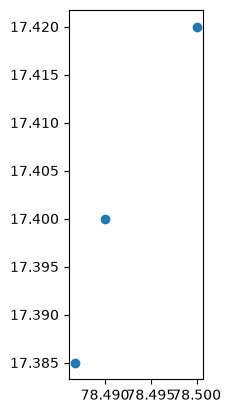

In [12]:
gdf.plot()

In [13]:
gdf.head()

,road_id,latitude,longitude,damage_level,geometry
0,R001,17.385,78.4867,Low,POINT (78.4867 17.385)
1,R002,17.400,78.4900,High,POINT (78.49 17.4)
2,R003,17.420,78.5000,Medium,POINT (78.5 17.42)


In [14]:
gdf.head()

,road_id,latitude,longitude,damage_level,geometry
0,R001,17.385,78.4867,Low,POINT (78.4867 17.385)
1,R002,17.400,78.4900,High,POINT (78.49 17.4)
2,R003,17.420,78.5000,Medium,POINT (78.5 17.42)


In [15]:
gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: >

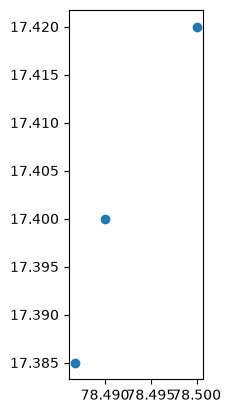

In [16]:
gdf.plot()

In [17]:
gdf["damage_level"].value_counts()

damage_level
Low       1
High      1
Medium    1
Name: count, dtype: int64

In [18]:
damage_mapping = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

gdf["damage_score"] = gdf["damage_level"].map(damage_mapping)

gdf

,road_id,latitude,longitude,damage_level,geometry,damage_score
0,R001,17.385,78.4867,Low,POINT (78.4867 17.385),1
1,R002,17.400,78.4900,High,POINT (78.49 17.4),3
2,R003,17.420,78.5000,Medium,POINT (78.5 17.42),2


In [19]:
gdf[["road_id", "damage_level", "damage_score"]]

,road_id,damage_level,damage_score
0,R001,Low,1
1,R002,High,3
2,R003,Medium,2


In [20]:
gdf.columns

Index(['road_id', 'latitude', 'longitude', 'damage_level', 'geometry',
       'damage_score'],
      dtype='str')

In [1]:
import os
print(os.listdir("../"))


['.venv', 'data', 'models', 'notebook', 'src', 'web']


In [2]:
import os
print(os.listdir("../data"))

[]


In [1]:
print("GeoShield is connected!")

GeoShield is connected!


In [2]:
import os

dataset_path = "../data/RDD2022-India.v5-rdd2022-india.voc"

print(os.path.exists(dataset_path))

True


In [3]:
import os

print(os.listdir(dataset_path))

['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [4]:
train_path = os.path.join(dataset_path, "train")

print(os.listdir(train_path)[:10])

['India_000000_jpg.rf.69b36e62b710e005430c9f0d94b155e9.jpg', 'India_000000_jpg.rf.69b36e62b710e005430c9f0d94b155e9.xml', 'India_000001_jpg.rf.92271e1b536bf333fbbe179e9ec36696.jpg', 'India_000001_jpg.rf.92271e1b536bf333fbbe179e9ec36696.xml', 'India_000002_jpg.rf.8c822c70f05ab38f0eaa3ca514e02c34.jpg', 'India_000002_jpg.rf.8c822c70f05ab38f0eaa3ca514e02c34.xml', 'India_000003_jpg.rf.58161f9ccf85eb7a03b0df0312c43d4f.jpg', 'India_000003_jpg.rf.58161f9ccf85eb7a03b0df0312c43d4f.xml', 'India_000007_jpg.rf.e0f57853f838e81985b88d63e43a1205.jpg', 'India_000007_jpg.rf.e0f57853f838e81985b88d63e43a1205.xml']


In [5]:
import xml.etree.ElementTree as ET

xml_file = os.path.join(
    train_path,
    "India_000000_jpg.rf.69b36e62b710e005430c9f0d94b155e9.xml"
)

tree = ET.parse(xml_file)
root = tree.getroot()

print(root.find("filename").text)

India_000000_jpg.rf.69b36e62b710e005430c9f0d94b155e9.jpg


In [6]:
objects = root.findall("object")

print("Number of damage objects:", len(objects))

Number of damage objects: 0


In [7]:
print([child.tag for child in root])

['folder', 'filename', 'path', 'source', 'size', 'segmented', 'metadata']


In [8]:
for file in os.listdir(train_path):
    if file.endswith(".xml"):
        test_xml = os.path.join(train_path, file)
        test_tree = ET.parse(test_xml)
        test_root = test_tree.getroot()

        if test_root.findall("object"):
            print("Found annotated file:", file)
            print("Number of objects:", len(test_root.findall("object")))
            break

Found annotated file: India_000010_jpg.rf.563d3deae64a20ea16c9de26da817125.xml
Number of objects: 1


In [9]:
obj = test_root.findall("object")[0]

print("Damage type:", obj.find("name").text)

Damage type: D44


In [10]:
bbox = obj.find("bndbox")

print("xmin:", bbox.find("xmin").text)
print("ymin:", bbox.find("ymin").text)
print("xmax:", bbox.find("xmax").text)
print("ymax:", bbox.find("ymax").text)

xmin: 461
ymin: 520
xmax: 494
ymax: 573


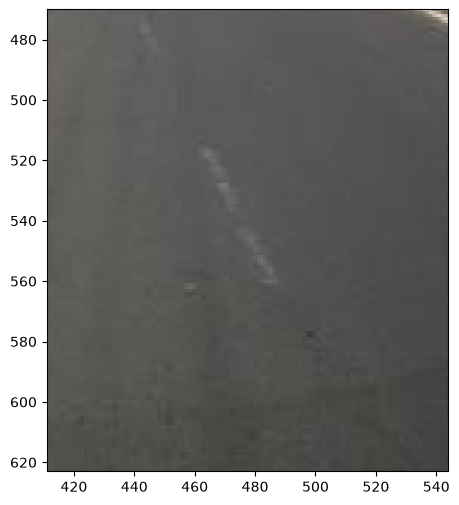

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

image_file = os.path.join(
    train_path,
    "India_000010_jpg.rf.563d3deae64a20ea16c9de26da817125.jpg"
)

image = Image.open(image_file)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.xlim(461 - 50, 494 + 50)
plt.ylim(573 + 50, 520 - 50)
plt.show()

In [12]:
xml_files = [f for f in os.listdir(train_path) if f.endswith(".xml")]

print("Total annotation files:", len(xml_files))

Total annotation files: 6532


In [13]:
from collections import Counter

damage_types = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        damage_types.append(obj.find("name").text)

damage_counts = Counter(damage_types)

print(damage_counts)

Counter({'D40': 2680, 'D20': 1706, 'D00': 1316, 'D44': 909, 'D01': 164, 'D10': 58, 'D43': 55, 'D11': 35, 'D50': 24, 'D0w0': 1})


In [14]:
for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        if obj.find("name").text == "D0w0":
            print("D0w0 found in:", xml_file)

D0w0 found in: India_006389_jpg.rf.dd5ea707e3916358c7e19f06ad57b418.xml


In [15]:
xml_path = os.path.join(
    train_path,
    "India_006389_jpg.rf.dd5ea707e3916358c7e19f06ad57b418.xml"
)

tree = ET.parse(xml_path)
root = tree.getroot()

for obj in root.findall("object"):
    print("Damage type:", obj.find("name").text)
    print("Bounding box:",
          obj.find("bndbox").find("xmin").text,
          obj.find("bndbox").find("ymin").text,
          obj.find("bndbox").find("xmax").text,
          obj.find("bndbox").find("ymax").text)

Damage type: D0w0
Bounding box: 455 490 570 663


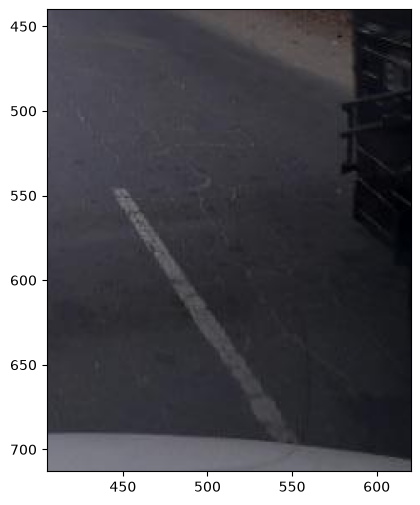

In [16]:
image_file = os.path.join(
    train_path,
    "India_006389_jpg.rf.dd5ea707e3916358c7e19f06ad57b418.jpg"
)

image = Image.open(image_file)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.xlim(455 - 50, 570 + 50)
plt.ylim(663 + 50, 490 - 50)
plt.show()

In [17]:
readme_path = os.path.join(dataset_path, "README.dataset.txt")

with open(readme_path, "r", encoding="utf-8") as f:
    readme_text = f.read()

print(readme_text[:5000])

# RDD2022-India > RDD2022-India
https://universe.roboflow.com/prakhar-kpb1v/rdd2022-india-il8ju

Provided by a Roboflow user
License: CC BY 4.0




In [18]:
readme_path = os.path.join(dataset_path, "README.roboflow.txt")

with open(readme_path, "r", encoding="utf-8") as f:
    readme_text = f.read()

print(readme_text[:5000])


RDD2022-India - v5 RDD2022-India

This dataset was exported via roboflow.com on April 9, 2026 at 5:56 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com

The dataset includes 7706 images.
Decays are annotated in Pascal VOC format.

The following pre-processing was applied to each image:

No image augmentation techniques were applied.





In [19]:
for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    image_count = len([
        f for f in os.listdir(split_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    xml_count = len([
        f for f in os.listdir(split_path)
        if f.lower().endswith(".xml")
    ])

    print(split, "→ images:", image_count, "| annotations:", xml_count)

train → images: 6532 | annotations: 6532
valid → images: 786 | annotations: 786
test → images: 388 | annotations: 388


In [20]:
valid_path = os.path.join(dataset_path, "valid")

valid_xml_files = [
    f for f in os.listdir(valid_path)
    if f.endswith(".xml")
]

valid_damage_types = []

for xml_file in valid_xml_files:
    xml_path = os.path.join(valid_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        valid_damage_types.append(obj.find("name").text)

print(Counter(valid_damage_types))

Counter({'D40': 340, 'D20': 215, 'D00': 172, 'D44': 113, 'D01': 10, 'D11': 8, 'D10': 5, 'D43': 2, 'D50': 2})


In [21]:
test_path = os.path.join(dataset_path, "test")

test_xml_files = [
    f for f in os.listdir(test_path)
    if f.endswith(".xml")
]

test_damage_types = []

for xml_file in test_xml_files:
    xml_path = os.path.join(test_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        test_damage_types.append(obj.find("name").text)

print(Counter(test_damage_types))

Counter({'D40': 167, 'D20': 100, 'D00': 67, 'D44': 40, 'D10': 5, 'D01': 5, 'D50': 2, 'D11': 2})


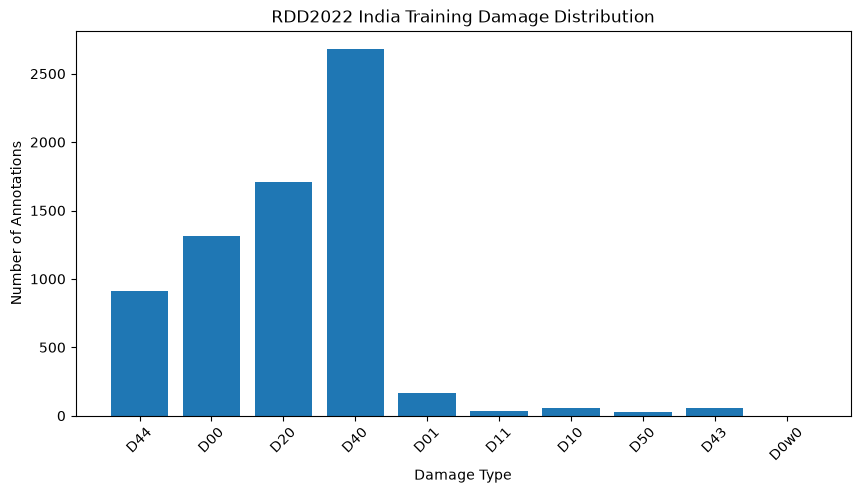

In [22]:
plt.figure(figsize=(10, 5))

plt.bar(damage_counts.keys(), damage_counts.values())

plt.xlabel("Damage Type")
plt.ylabel("Number of Annotations")
plt.title("RDD2022 India Training Damage Distribution")

plt.xticks(rotation=45)
plt.show()

In [24]:
import pandas as pd

In [25]:
import pandas as pd
print("Pandas is ready:", pd.__version__)

Pandas is ready: 3.0.6


In [26]:
from collections import Counter
import os
import xml.etree.ElementTree as ET

train_path = os.path.join(dataset_path, "train")

xml_files = [
    f for f in os.listdir(train_path)
    if f.endswith(".xml")
]

damage_types = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        damage_types.append(obj.find("name").text)

damage_counts = Counter(damage_types)

print(damage_counts)

Counter({'D40': 2680, 'D20': 1706, 'D00': 1316, 'D44': 909, 'D01': 164, 'D10': 58, 'D43': 55, 'D11': 35, 'D50': 24, 'D0w0': 1})


In [27]:
label_summary = pd.DataFrame(
    list(damage_counts.items()),
    columns=["Damage Type", "Annotation Count"]
)

label_summary

,Damage Type,Annotation Count
0,D44,909
1,D00,1316
2,D20,1706
3,D40,2680
4,D01,164
5,D11,35
6,D10,58
7,D50,24
8,D43,55
9,D0w0,1


In [28]:
label_meanings = {
    "D00": "Longitudinal crack",
    "D01": "Longitudinal crack with other damage",
    "D10": "Transverse crack",
    "D11": "Transverse crack with other damage",
    "D20": "Alligator crack",
    "D40": "Pothole",
    "D43": "Crosswalk blur",
    "D44": "White line blur",
    "D50": "Other damage",
    "D0w0": "Unknown/rare label"
}

label_summary["Meaning"] = label_summary["Damage Type"].map(label_meanings)

label_summary

,Damage Type,Annotation Count,Meaning
0,D44,909,White line blur
1,D00,1316,Longitudinal crack
2,D20,1706,Alligator crack
3,D40,2680,Pothole
4,D01,164,Longitudinal crack with other damage
5,D11,35,Transverse crack with other damage
6,D10,58,Transverse crack
7,D50,24,Other damage
8,D43,55,Crosswalk blur
9,D0w0,1,Unknown/rare label


In [29]:
core_labels = {"D00", "D10", "D20", "D40"}

core_image_count = 0

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    labels_in_image = {
        obj.find("name").text
        for obj in root.findall("object")
    }

    if labels_in_image & core_labels:
        core_image_count += 1

print("Training images with core damage:", core_image_count)

Training images with core damage: 2738


In [30]:
core_image_counts = Counter()

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    labels_in_image = {
        obj.find("name").text
        for obj in root.findall("object")
    }

    for label in labels_in_image & core_labels:
        core_image_counts[label] += 1

print(core_image_counts)

Counter({'D20': 1486, 'D40': 1296, 'D00': 946, 'D10': 51})


Image: India_000011_jpg.rf.c0a3a9ad2602862cf878c8f4c800979a.jpg


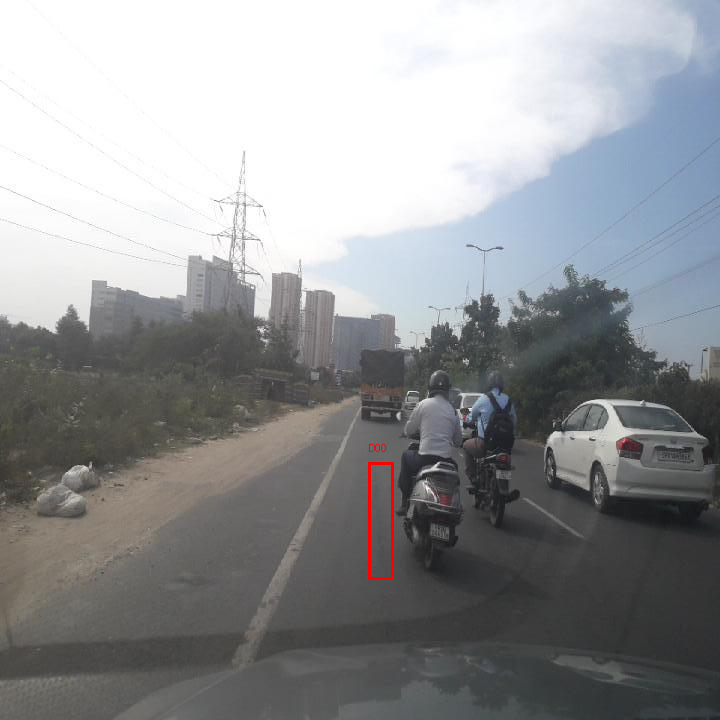

In [31]:
from PIL import Image, ImageDraw

# Find the first training image containing a core damage label
for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    objects = root.findall("object")

    if any(obj.find("name").text in core_labels for obj in objects):
        image_name = root.find("filename").text
        image_path = os.path.join(train_path, image_name)

        image = Image.open(image_path).convert("RGB")
        draw = ImageDraw.Draw(image)

        for obj in objects:
            label = obj.find("name").text

            if label in core_labels:
                bbox = obj.find("bndbox")

                xmin = int(bbox.find("xmin").text)
                ymin = int(bbox.find("ymin").text)
                xmax = int(bbox.find("xmax").text)
                ymax = int(bbox.find("ymax").text)

                draw.rectangle(
                    [xmin, ymin, xmax, ymax],
                    outline="red",
                    width=3
                )

                draw.text(
                    (xmin, max(0, ymin - 20)),
                    label,
                    fill="red"
                )

        print("Image:", image_name)
        display(image)
        break

In [32]:
core_summary = pd.DataFrame(
    list(core_image_counts.items()),
    columns=["Damage Type", "Images"]
)

core_summary

,Damage Type,Images
0,D00,946
1,D20,1486
2,D40,1296
3,D10,51


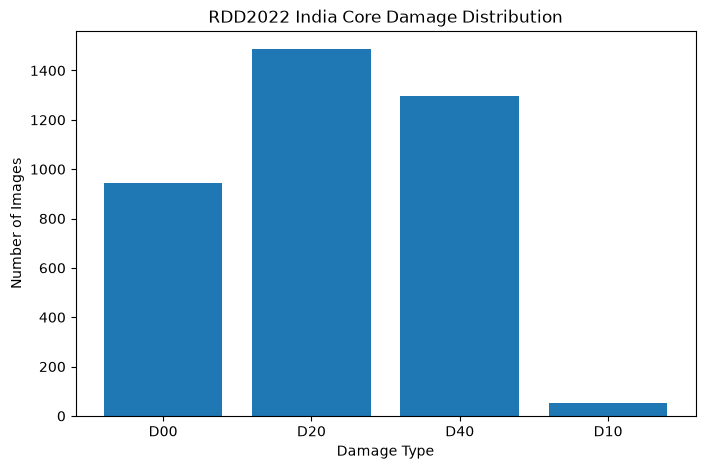

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    core_summary["Damage Type"],
    core_summary["Images"]
)

plt.xlabel("Damage Type")
plt.ylabel("Number of Images")
plt.title("RDD2022 India Core Damage Distribution")

plt.show()

In [34]:
from PIL import Image

# Get the first training image
first_image = [
    f for f in os.listdir(train_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
][0]

image_path = os.path.join(train_path, first_image)

image = Image.open(image_path)

print("Image:", first_image)
print("Width:", image.width)
print("Height:", image.height)
print("Mode:", image.mode)

Image: India_000000_jpg.rf.69b36e62b710e005430c9f0d94b155e9.jpg
Width: 720
Height: 720
Mode: RGB


In [35]:
from collections import Counter

image_sizes = []

for file in os.listdir(train_path):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        image_path = os.path.join(train_path, file)
        with Image.open(image_path) as img:
            image_sizes.append(img.size)

size_counts = Counter(image_sizes)

print("Number of images checked:", len(image_sizes))
print("Different image sizes:", len(size_counts))
print("Most common sizes:")

for size, count in size_counts.most_common(10):
    print(size, "→", count, "images")

Number of images checked: 6532
Different image sizes: 1
Most common sizes:
(720, 720) → 6532 images


In [36]:
objects_per_image = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    object_count = len(root.findall("object"))
    objects_per_image.append(object_count)

object_count_summary = Counter(objects_per_image)

print("Images checked:", len(objects_per_image))
print("Total damage annotations:", sum(objects_per_image))
print("Images with no damage:", object_count_summary.get(0, 0))
print("Images with 1 damage:", object_count_summary.get(1, 0))
print("Images with 2 damages:", object_count_summary.get(2, 0))
print("Images with 3 damages:", object_count_summary.get(3, 0))
print("Maximum damages in one image:", max(objects_per_image))

Images checked: 6532
Total damage annotations: 6948
Images with no damage: 3313
Images with 1 damage: 1379
Images with 2 damages: 929
Images with 3 damages: 445
Maximum damages in one image: 14


In [37]:
print("Damage objects per image:")

for count in sorted(object_count_summary):
    print(f"{count} damage objects → {object_count_summary[count]} images")

Damage objects per image:
0 damage objects → 3313 images
1 damage objects → 1379 images
2 damage objects → 929 images
3 damage objects → 445 images
4 damage objects → 232 images
5 damage objects → 108 images
6 damage objects → 47 images
7 damage objects → 45 images
8 damage objects → 16 images
9 damage objects → 10 images
10 damage objects → 4 images
13 damage objects → 3 images
14 damage objects → 1 images


In [38]:
average_objects = sum(objects_per_image) / len(objects_per_image)

print("Average damage objects per image:", round(average_objects, 2))

Average damage objects per image: 1.06


Image: India_000014_jpg.rf.11ec2902308ab72dfec3fea1753a04c8.jpg
Number of damage objects: 3


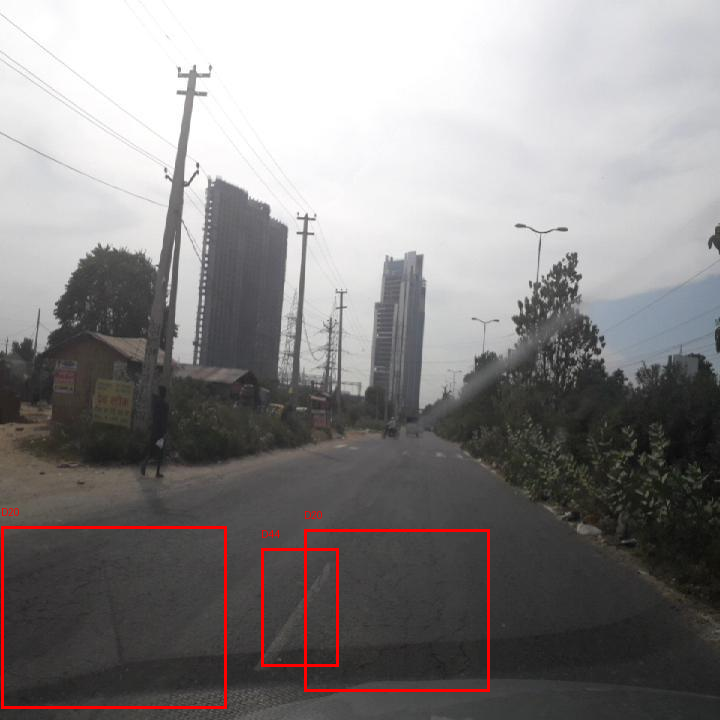

In [39]:
from PIL import Image, ImageDraw

# Find an image containing at least 2 damage objects
for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()
    objects = root.findall("object")

    if len(objects) >= 2:
        image_name = root.find("filename").text
        image_path = os.path.join(train_path, image_name)

        image = Image.open(image_path).convert("RGB")
        draw = ImageDraw.Draw(image)

        for obj in objects:
            label = obj.find("name").text
            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            draw.rectangle(
                [xmin, ymin, xmax, ymax],
                outline="red",
                width=3
            )

            draw.text(
                (xmin, max(0, ymin - 20)),
                label,
                fill="red"
            )

        print("Image:", image_name)
        print("Number of damage objects:", len(objects))

        display(image)
        break

In [40]:
print("Core damage labels found:")

for label in sorted(core_labels):
    print(label, "→", damage_counts.get(label, 0), "annotations")

Core damage labels found:
D00 → 1316 annotations
D10 → 58 annotations
D20 → 1706 annotations
D40 → 2680 annotations


In [41]:
core_total = sum(
    damage_counts[label]
    for label in core_labels
)

core_percentages = {
    label: round((damage_counts[label] / core_total) * 100, 2)
    for label in sorted(core_labels)
}

print("Core annotation total:", core_total)
print("Core class percentages:")

for label, percentage in core_percentages.items():
    print(label, "→", percentage, "%")

Core annotation total: 5760
Core class percentages:
D00 → 22.85 %
D10 → 1.01 %
D20 → 29.62 %
D40 → 46.53 %


In [42]:
core_summary = pd.DataFrame({
    "Damage Type": sorted(core_labels),
    "Annotation Count": [
        damage_counts[label]
        for label in sorted(core_labels)
    ],
    "Percentage": [
        core_percentages[label]
        for label in sorted(core_labels)
    ]
})

core_summary

,Damage Type,Annotation Count,Percentage
0,D00,1316,22.85
1,D10,58,1.01
2,D20,1706,29.62
3,D40,2680,46.53


In [43]:
invalid_boxes = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        label = obj.find("name").text
        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        if (
            xmin < 0 or ymin < 0 or
            xmax > 720 or ymax > 720 or
            xmin >= xmax or ymin >= ymax
        ):
            invalid_boxes.append({
                "file": xml_file,
                "label": label,
                "bbox": (xmin, ymin, xmax, ymax)
            })

print("Total invalid bounding boxes:", len(invalid_boxes))

Total invalid bounding boxes: 0


In [44]:
for split in ["valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    invalid_count = 0
    total_objects = 0

    for xml_file in os.listdir(split_path):
        if not xml_file.endswith(".xml"):
            continue

        xml_path = os.path.join(split_path, xml_file)

        tree = ET.parse(xml_path)
        root = tree.getroot()

        for obj in root.findall("object"):
            total_objects += 1

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            if (
                xmin < 0 or ymin < 0 or
                xmax > 720 or ymax > 720 or
                xmin >= xmax or ymin >= ymax
            ):
                invalid_count += 1

    print(
        split,
        "→ total objects:", total_objects,
        "| invalid boxes:", invalid_count
    )

valid → total objects: 867 | invalid boxes: 0
test → total objects: 388 | invalid boxes: 0


In [45]:
for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(split_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    annotations = {
        os.path.splitext(f)[0]
        for f in os.listdir(split_path)
        if f.lower().endswith(".xml")
    }

    missing_annotations = images - annotations
    missing_images = annotations - images

    print(f"{split}:")
    print("  Images:", len(images))
    print("  Annotations:", len(annotations))
    print("  Images without annotations:", len(missing_annotations))
    print("  Annotations without images:", len(missing_images))

train:
  Images: 6532
  Annotations: 6532
  Images without annotations: 0
  Annotations without images: 0
valid:
  Images: 786
  Annotations: 786
  Images without annotations: 0
  Annotations without images: 0
test:
  Images: 388
  Annotations: 388
  Images without annotations: 0
  Annotations without images: 0


In [46]:
for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    split_counts = Counter()

    for xml_file in os.listdir(split_path):
        if not xml_file.endswith(".xml"):
            continue

        xml_path = os.path.join(split_path, xml_file)

        tree = ET.parse(xml_path)
        root = tree.getroot()

        for obj in root.findall("object"):
            label = obj.find("name").text
            split_counts[label] += 1

    print(f"\n{split.upper()} label counts:")
    
    for label, count in sorted(split_counts.items()):
        print(f"{label}: {count}")


TRAIN label counts:
D00: 1316
D01: 164
D0w0: 1
D10: 58
D11: 35
D20: 1706
D40: 2680
D43: 55
D44: 909
D50: 24

VALID label counts:
D00: 172
D01: 10
D10: 5
D11: 8
D20: 215
D40: 340
D43: 2
D44: 113
D50: 2

TEST label counts:
D00: 67
D01: 5
D10: 5
D11: 2
D20: 100
D40: 167
D44: 40
D50: 2


In [47]:
core_labels = ["D00", "D10", "D20", "D40"]

split_counts = {}

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)
    counts = Counter()

    for xml_file in os.listdir(split_path):
        if not xml_file.endswith(".xml"):
            continue

        xml_path = os.path.join(split_path, xml_file)

        tree = ET.parse(xml_path)
        root = tree.getroot()

        for obj in root.findall("object"):
            label = obj.find("name").text
            counts[label] += 1

    split_counts[split] = counts

core_split_summary = pd.DataFrame({
    "Damage Type": core_labels,
    "Train": [split_counts["train"][label] for label in core_labels],
    "Valid": [split_counts["valid"][label] for label in core_labels],
    "Test": [split_counts["test"][label] for label in core_labels]
})

core_split_summary

,Damage Type,Train,Valid,Test
0,D00,1316,172,67
1,D10,58,5,5
2,D20,1706,215,100
3,D40,2680,340,167


In [48]:
split_summary = []

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    image_count = len([
        f for f in os.listdir(split_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    split_summary.append({
        "Split": split,
        "Images": image_count
    })

split_summary = pd.DataFrame(split_summary)

total_images = split_summary["Images"].sum()

split_summary["Percentage"] = (
    split_summary["Images"] / total_images * 100
).round(2)

print("Total images:", total_images)

split_summary

Total images: 7706


,Split,Images,Percentage
0,train,6532,84.77
1,valid,786,10.20
2,test,388,5.04


In [49]:
summary_path = os.path.join(dataset_path, "dataset_split_summary.csv")

split_summary.to_csv(summary_path, index=False)

print("Saved:", summary_path)

Saved: ../data/RDD2022-India.v5-rdd2022-india.voc\dataset_split_summary.csv


In [50]:
# Find the first training XML file that contains at least one damage object
for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    objects = root.findall("object")

    if objects:
        print("Annotation file:", xml_file)
        print("Image:", root.find("filename").text)

        size = root.find("size")
        print(
            "Image size:",
            size.find("width").text,
            "x",
            size.find("height").text
        )

        for i, obj in enumerate(objects, start=1):
            label = obj.find("name").text
            bbox = obj.find("bndbox")

            print(f"\nObject {i}")
            print("Label:", label)
            print("Bounding box:")
            print("  xmin:", bbox.find("xmin").text)
            print("  ymin:", bbox.find("ymin").text)
            print("  xmax:", bbox.find("xmax").text)
            print("  ymax:", bbox.find("ymax").text)

        break

Annotation file: India_000010_jpg.rf.563d3deae64a20ea16c9de26da817125.xml
Image: India_000010_jpg.rf.563d3deae64a20ea16c9de26da817125.jpg
Image size: 720 x 720

Object 1
Label: D44
Bounding box:
  xmin: 461
  ymin: 520
  xmax: 494
  ymax: 573


In [51]:
box_sizes = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        width = xmax - xmin
        height = ymax - ymin
        area = width * height

        box_sizes.append({
            "width": width,
            "height": height,
            "area": area
        })

box_df = pd.DataFrame(box_sizes)

print("Total bounding boxes:", len(box_df))
print("Average width:", round(box_df["width"].mean(), 2))
print("Average height:", round(box_df["height"].mean(), 2))
print("Average area:", round(box_df["area"].mean(), 2))

Total bounding boxes: 6948
Average width: 167.83
Average height: 108.36
Average area: 24131.34


In [52]:
print("Bounding-box width:")
print("  Minimum:", box_df["width"].min())
print("  Median:", box_df["width"].median())
print("  Maximum:", box_df["width"].max())

print("\nBounding-box height:")
print("  Minimum:", box_df["height"].min())
print("  Median:", box_df["height"].median())
print("  Maximum:", box_df["height"].max())

print("\nBounding-box area:")
print("  Minimum:", box_df["area"].min())
print("  Median:", box_df["area"].median())
print("  Maximum:", box_df["area"].max())

Bounding-box width:
  Minimum: 16
  Median: 111.0
  Maximum: 719

Bounding-box height:
  Minimum: 12
  Median: 94.0
  Maximum: 535

Bounding-box area:
  Minimum: 304
  Median: 9841.5
  Maximum: 346368


In [53]:
core_box_stats = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        label = obj.find("name").text

        if label not in core_labels:
            continue

        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        width = xmax - xmin
        height = ymax - ymin
        area = width * height

        core_box_stats.append({
            "Damage Type": label,
            "Width": width,
            "Height": height,
            "Area": area
        })

core_box_df = pd.DataFrame(core_box_stats)

core_box_summary = (
    core_box_df
    .groupby("Damage Type")
    .agg(
        Annotations=("Area", "count"),
        Average_Width=("Width", "mean"),
        Average_Height=("Height", "mean"),
        Average_Area=("Area", "mean")
    )
    .round(2)
)

core_box_summary

,Annotations,Average_Width,Average_Height,Average_Area
Damage Type,,,,
D00,1316,95.30,131.73,14524.73
D10,58,233.83,46.95,12218.97
D20,1706,330.33,164.42,59053.54
D40,2680,120.31,67.40,11889.94


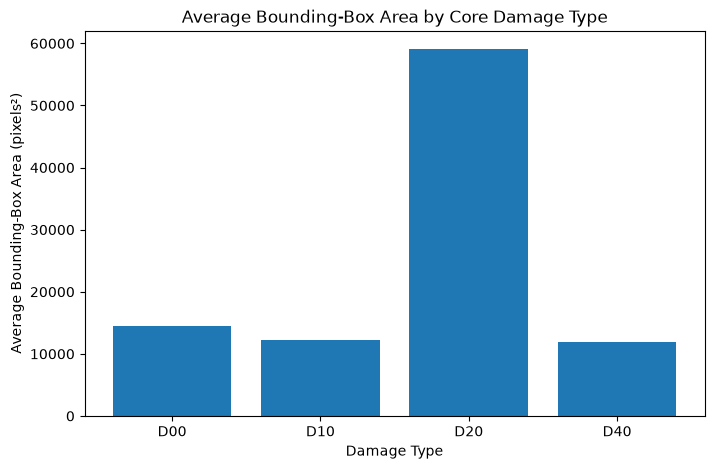

In [54]:
core_area_plot = core_box_summary.reset_index()

plt.figure(figsize=(8, 5))

plt.bar(
    core_area_plot["Damage Type"],
    core_area_plot["Average_Area"]
)

plt.xlabel("Damage Type")
plt.ylabel("Average Bounding-Box Area (pixels²)")
plt.title("Average Bounding-Box Area by Core Damage Type")

plt.show()

In [55]:
box_summary_path = os.path.join(
    dataset_path,
    "core_damage_box_summary.csv"
)

core_box_summary.to_csv(box_summary_path)

print("Saved:", box_summary_path)

Saved: ../data/RDD2022-India.v5-rdd2022-india.voc\core_damage_box_summary.csv


In [56]:
core_label_meanings = {
    "D00": "Longitudinal crack",
    "D10": "Transverse crack",
    "D20": "Alligator crack",
    "D40": "Pothole"
}

for label, meaning in core_label_meanings.items():
    print(f"{label}: {meaning}")

D00: Longitudinal crack
D10: Transverse crack
D20: Alligator crack
D40: Pothole


In [58]:
core_counts = {
    label: damage_counts[label]
    for label in ["D00", "D10", "D20", "D40"]
}

print(core_counts)

{'D00': 1316, 'D10': 58, 'D20': 1706, 'D40': 2680}


In [59]:
core_summary = pd.DataFrame({
    "Damage Type": list(core_counts.keys()),
    "Annotation Count": list(core_counts.values())
})

core_summary["Percentage"] = (
    core_summary["Annotation Count"]
    / core_summary["Annotation Count"].sum()
    * 100
)

core_summary

,Damage Type,Annotation Count,Percentage
0,D00,1316,22.847222
1,D10,58,1.006944
2,D20,1706,29.618056
3,D40,2680,46.527778


In [60]:
core_summary_path = os.path.join(
    dataset_path,
    "core_damage_summary.csv"
)

core_summary.to_csv(core_summary_path, index=False)

print("Saved:", core_summary_path)

Saved: ../data/RDD2022-India.v5-rdd2022-india.voc\core_damage_summary.csv


In [61]:
core_image_counts = {label: 0 for label in core_counts}

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    labels_in_image = {
        obj.find("name").text
        for obj in root.findall("object")
    }

    for label in core_counts:
        if label in labels_in_image:
            core_image_counts[label] += 1

print(core_image_counts)

{'D00': 946, 'D10': 51, 'D20': 1486, 'D40': 1296}


In [62]:
core_images_with_damage = 0

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    labels_in_image = {
        obj.find("name").text
        for obj in root.findall("object")
    }

    if labels_in_image.intersection(core_counts.keys()):
        core_images_with_damage += 1

print("Training images with at least one core damage:", core_images_with_damage)

Training images with at least one core damage: 2738


In [63]:
core_damage_percentage = (
    core_images_with_damage / len(xml_files)
) * 100

print(f"Training images with core damage: {core_damage_percentage:.2f}%")

Training images with core damage: 41.92%


In [64]:
from collections import Counter

object_counts_per_image = []

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    object_count = len(root.findall("object"))
    object_counts_per_image.append(object_count)

object_count_distribution = Counter(object_counts_per_image)

for count in sorted(object_count_distribution):
    print(
        f"{count} damage objects → "
        f"{object_count_distribution[count]} images"
    )

0 damage objects → 3313 images
1 damage objects → 1379 images
2 damage objects → 929 images
3 damage objects → 445 images
4 damage objects → 232 images
5 damage objects → 108 images
6 damage objects → 47 images
7 damage objects → 45 images
8 damage objects → 16 images
9 damage objects → 10 images
10 damage objects → 4 images
13 damage objects → 3 images
14 damage objects → 1 images


In [65]:
average_objects = sum(object_counts_per_image) / len(object_counts_per_image)

print(f"Average damage objects per training image: {average_objects:.2f}")

Average damage objects per training image: 1.06


In [66]:
from PIL import Image

image_sizes = Counter()

for file in os.listdir(train_path):
    if file.lower().endswith(".jpg"):
        image_path = os.path.join(train_path, file)

        with Image.open(image_path) as img:
            image_sizes[img.size] += 1

print("Different image sizes:", len(image_sizes))

for size, count in image_sizes.items():
    print(f"{size} → {count} images")

Different image sizes: 1
(720, 720) → 6532 images


In [67]:
image_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(train_path)
    if f.lower().endswith(".jpg")
}

annotation_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(train_path)
    if f.lower().endswith(".xml")
}

missing_annotations = image_files - annotation_files
missing_images = annotation_files - image_files

print("Training images:", len(image_files))
print("Training annotations:", len(annotation_files))
print("Images without annotations:", len(missing_annotations))
print("Annotations without images:", len(missing_images))

Training images: 6532
Training annotations: 6532
Images without annotations: 0
Annotations without images: 0


In [68]:
invalid_boxes = 0
total_boxes = 0

for xml_file in xml_files:
    xml_path = os.path.join(train_path, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find("size")
    image_width = int(size.find("width").text)
    image_height = int(size.find("height").text)

    for obj in root.findall("object"):
        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        total_boxes += 1

        if (
            xmin < 0 or
            ymin < 0 or
            xmax > image_width or
            ymax > image_height or
            xmin >= xmax or
            ymin >= ymax
        ):
            invalid_boxes += 1

print("Total bounding boxes:", total_boxes)
print("Invalid bounding boxes:", invalid_boxes)

Total bounding boxes: 6948
Invalid bounding boxes: 0


In [69]:
bbox_validation = pd.DataFrame({
    "Metric": [
        "Training images",
        "Training annotations",
        "Total bounding boxes",
        "Invalid bounding boxes"
    ],
    "Value": [
        len(image_files),
        len(annotation_files),
        total_boxes,
        invalid_boxes
    ]
})

bbox_validation_path = os.path.join(
    dataset_path,
    "bounding_box_validation.csv"
)

bbox_validation.to_csv(bbox_validation_path, index=False)

print("Saved:", bbox_validation_path)

Saved: ../data/RDD2022-India.v5-rdd2022-india.voc\bounding_box_validation.csv


In [70]:
id="j7k3pz"
split_box_results = {}

for split in ["valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    total_boxes = 0
    invalid_boxes = 0

    for xml_file in os.listdir(split_path):
        if not xml_file.lower().endswith(".xml"):
            continue

        xml_path = os.path.join(split_path, xml_file)
        tree = ET.parse(xml_path)
        root = tree.getroot()

        size = root.find("size")
        image_width = int(size.find("width").text)
        image_height = int(size.find("height").text)

        for obj in root.findall("object"):
            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            total_boxes += 1

            if (
                xmin < 0 or
                ymin < 0 or
                xmax > image_width or
                ymax > image_height or
                xmin >= xmax or
                ymin >= ymax
            ):
                invalid_boxes += 1

    split_box_results[split] = (total_boxes, invalid_boxes)

for split, (total, invalid) in split_box_results.items():
    print(f"{split.capitalize()} total bounding boxes:", total)
    print(f"{split.capitalize()} invalid bounding boxes:", invalid)

Valid total bounding boxes: 867
Valid invalid bounding boxes: 0
Test total bounding boxes: 388
Test invalid bounding boxes: 0


In [71]:
split_label_counts = {}

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)
    labels = []

    for xml_file in os.listdir(split_path):
        if not xml_file.lower().endswith(".xml"):
            continue

        xml_path = os.path.join(split_path, xml_file)
        tree = ET.parse(xml_path)
        root = tree.getroot()

        for obj in root.findall("object"):
            labels.append(obj.find("name").text)

    split_label_counts[split] = Counter(labels)

all_labels = sorted(set().union(
    *[set(counts.keys()) for counts in split_label_counts.values()]
))

class_distribution = pd.DataFrame({
    "Damage Type": all_labels,
    "Train": [split_label_counts["train"].get(label, 0) for label in all_labels],
    "Valid": [split_label_counts["valid"].get(label, 0) for label in all_labels],
    "Test": [split_label_counts["test"].get(label, 0) for label in all_labels]
})

class_distribution

,Damage Type,Train,Valid,Test
0,D00,1316,172,67
1,D01,164,10,5
2,D0w0,1,0,0
3,D10,58,5,5
4,D11,35,8,2
5,D20,1706,215,100
6,D40,2680,340,167
7,D43,55,2,0
8,D44,909,113,40
9,D50,24,2,2


In [72]:
class_distribution_path = os.path.join(
    dataset_path,
    "class_distribution_all_splits.csv"
)

class_distribution.to_csv(
    class_distribution_path,
    index=False
)

print("Saved:", class_distribution_path)

Saved: ../data/RDD2022-India.v5-rdd2022-india.voc\class_distribution_all_splits.csv


In [73]:
dataset_report = pd.DataFrame({
    "Metric": [
        "Total images",
        "Training images",
        "Validation images",
        "Test images",
        "Training annotations",
        "Validation annotations",
        "Test annotations",
        "Image width",
        "Image height",
        "Core damage classes"
    ],
    "Value": [
        7706,
        6532,
        786,
        388,
        6948,
        867,
        388,
        720,
        720,
        "D00, D10, D20, D40"
    ]
})

dataset_report

,Metric,Value
0,Total images,7706
1,Training images,6532
2,Validation images,786
3,Test images,388
4,Training annotations,6948
5,Validation annotations,867
6,Test annotations,388
7,Image width,720
8,Image height,720
9,Core damage classes,"D00, D10, D20, D40"


In [74]:
dataset_report_path = os.path.join(
    dataset_path,
    "dataset_report.csv"
)

dataset_report.to_csv(
    dataset_report_path,
    index=False
)

print("Saved:", dataset_report_path)

Saved: ../data/RDD2022-India.v5-rdd2022-india.voc\dataset_report.csv


In [75]:
core_label_names = {
    "D00": "Longitudinal crack",
    "D10": "Transverse crack",
    "D20": "Alligator crack",
    "D40": "Pothole"
}

for code, name in core_label_names.items():
    print(f"{code} → {name}")

D00 → Longitudinal crack
D10 → Transverse crack
D20 → Alligator crack
D40 → Pothole


In [1]:
print("GeoShield is connected today!")


GeoShield is connected today!


In [2]:
import os

dataset_path = "../data/RDD2022-India.v5-rdd2022-india.voc"

print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


In [3]:
print(os.listdir(dataset_path))

['bounding_box_validation.csv', 'class_distribution_all_splits.csv', 'core_damage_box_summary.csv', 'core_damage_summary.csv', 'dataset_report.csv', 'dataset_split_summary.csv', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [4]:
core_label_names = {
    "D00": "Longitudinal crack",
    "D10": "Transverse crack",
    "D20": "Alligator crack",
    "D40": "Pothole"
}

for code, name in core_label_names.items():
    print(f"{code} → {name}")

D00 → Longitudinal crack
D10 → Transverse crack
D20 → Alligator crack
D40 → Pothole


In [5]:
train_path = os.path.join(dataset_path, "train")

print("Training folder exists:", os.path.exists(train_path))
print("Training files:", len(os.listdir(train_path)))

Training folder exists: True
Training files: 13064


In [6]:
try:
    import ultralytics
    print("Ultralytics is installed:", ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed.")

Ultralytics is not installed.
